# Student Performance Prediction

Predicting the final grade (G3) of students using the UCI Student Performance dataset.

**Dataset source: Kaggle, 'Math Students' (originally from the UCI Machine Learning Repository, Cortez and Silva, 2008)**


**Step 0:** Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

**Step 1:** Load the data

In [ ]:
df = pd.read_csv("Dataset/student-mat.csv", sep=",")
print(df.shape)
df.head()

(395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


**Step 2:** Check for missing values

In [6]:
# count missing values and duplicate rows
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.info()

Missing values: 0
Duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     39

**Step 3:** Explore the data (EDA)

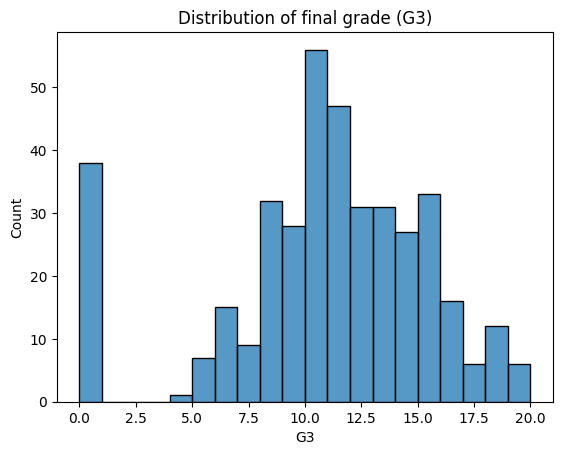

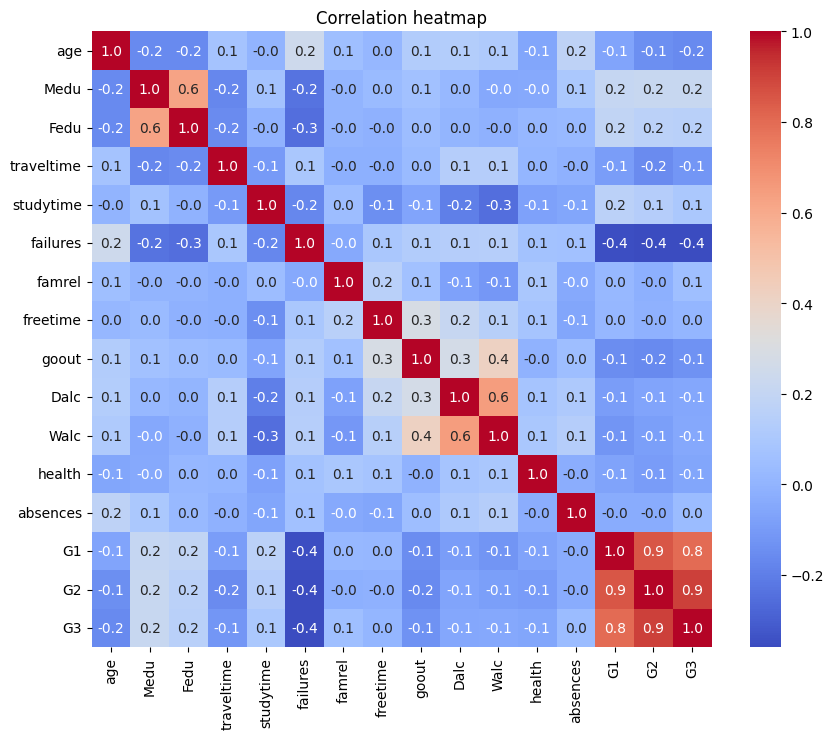

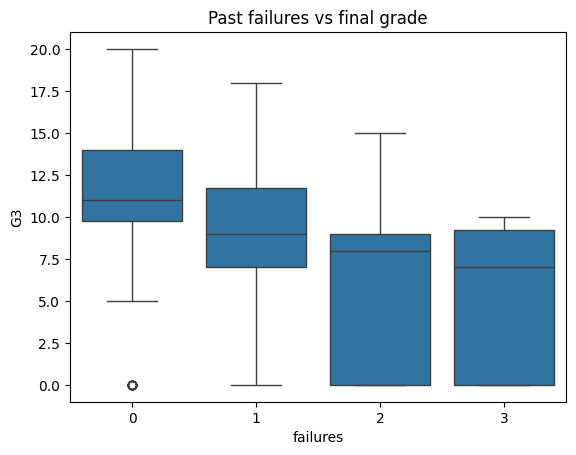

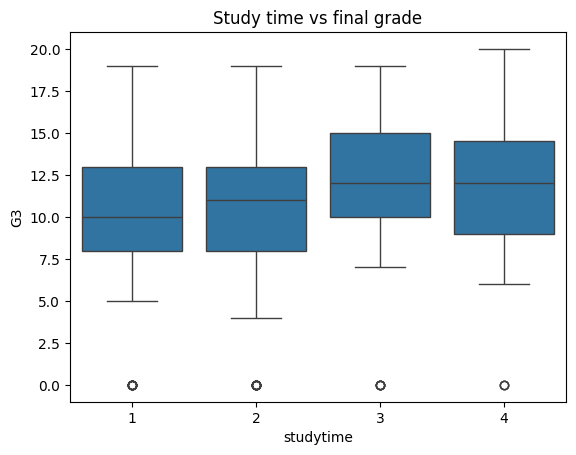

In [7]:
# 1. how final grades are spread out
sns.histplot(df["G3"], bins=20)
plt.title("Distribution of final grade (G3)")
plt.show()

# 2. correlation between numeric columns
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".1f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

# 3. past failures vs final grade
sns.boxplot(x="failures", y="G3", data=df)
plt.title("Past failures vs final grade")
plt.show()

# 4. study time vs final grade
sns.boxplot(x="studytime", y="G3", data=df)
plt.title("Study time vs final grade")
plt.show()

**Step 4:** Prepare the data and split into train and test

In [8]:
# models only understand numbers, so convert text columns (like "sex", "school") to 0/1 columns
df_model = pd.get_dummies(df, drop_first=True)

X = df_model.drop("G3", axis=1)   # inputs
y = df_model["G3"]                # what we want to predict

# keep 20% of students hidden for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(316, 41) (79, 41)


**Step 5:** Train and test both models

In [9]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

for name, pred in [("Linear Regression", lr_pred), ("Random Forest", rf_pred)]:
    print(name)
    print("  MAE:", round(mean_absolute_error(y_test, pred), 2))
    print("  R2 :", round(r2_score(y_test, pred), 2))

Linear Regression
  MAE: 1.65
  R2 : 0.72
Random Forest
  MAE: 1.16
  R2 : 0.81


**Step 6:** Results and important features

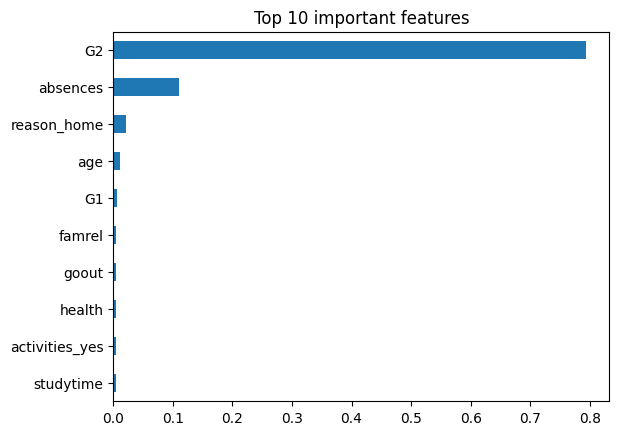

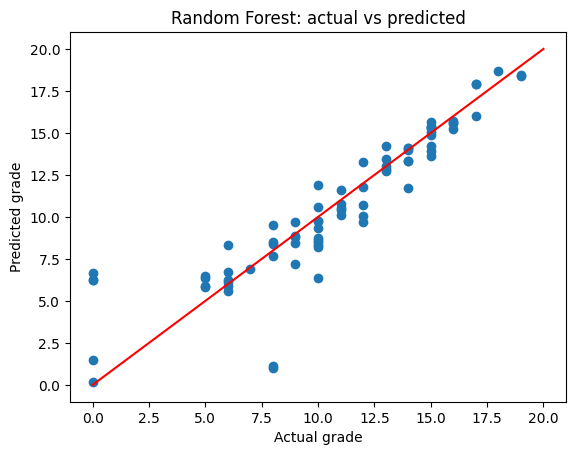

In [10]:
# which columns mattered most to the Random Forest
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importance.tail(10).plot(kind="barh")
plt.title("Top 10 important features")
plt.show()

# actual vs predicted grades
plt.scatter(y_test, rf_pred)
plt.plot([0, 20], [0, 20], color="red")
plt.xlabel("Actual grade")
plt.ylabel("Predicted grade")
plt.title("Random Forest: actual vs predicted")
plt.show()

In [13]:
def ask_number(question, low, high):
    # keeps asking until the user types a number inside the allowed range
    while True:
        try:
            value = float(input(question + " "))
            if low <= value <= high:
                return value
            print(f"  Please enter a value between {low} and {high}.")
        except ValueError:
            print("  Please enter a number.")

def ask_yes_no(question):
    while True:
        answer = input(question + " (yes/no): ").strip().lower()
        if answer in ("yes", "y"):
            return 1
        if answer in ("no", "n"):
            return 0
        print("  Please type yes or no.")

def predict_student():
    print("STUDENT PERFORMANCE PREDICTOR")
    print("Answer 6 short questions to get the expected final marks.\n")

    print("-- Academic record --")
    g1 = ask_number("1. Marks scored in the first term exam (0-20):", 0, 20)
    g2 = ask_number("2. Marks scored in the second term exam (0-20):", 0, 20)

    print("\n-- Study habits --")
    daily_hours = ask_number("3. How many hours does the student study per day (0-12)?", 0, 12)
    absences = ask_number("4. How many classes has the student missed this year (0-93)?", 0, 93)

    print("\n-- Motivation and lifestyle --")
    higher = ask_yes_no("5. Does the student plan to pursue higher education?")
    goout = ask_number("6. How often does the student go out with friends "
                       "(1 = very rarely, 5 = very often)?", 1, 5)

    # the dataset stores study time in weekly ranges, so convert daily hours to that range
    weekly = daily_hours * 7
    if weekly < 2:
        studytime = 1
    elif weekly <= 5:
        studytime = 2
    elif weekly <= 10:
        studytime = 3
    else:
        studytime = 4

    # all other columns get the typical (median) value from the training data
    row = X_train.astype(float).median().to_frame().T
    row["G1"] = g1
    row["G2"] = g2
    row["studytime"] = studytime
    row["absences"] = absences
    row["higher_yes"] = higher
    row["goout"] = goout
    row = row[X.columns]

    pred = min(max(rf.predict(row)[0], 0), 20)
    print("\n" + "=" * 40)
    print(f"Predicted final marks: {pred:.1f} out of 20")
    print(f"Expected range (model's typical error of about 1.2 marks): "
          f"{max(pred - 1.2, 0):.1f} to {min(pred + 1.2, 20):.1f}")
    print("=" * 40)

predict_student()

STUDENT PERFORMANCE PREDICTOR
Answer 6 short questions to get the expected final marks.

-- Academic record --
1. Marks scored in the first term exam (0-20): 18
2. Marks scored in the second term exam (0-20): 17

-- Study habits --
3. How many hours does the student study per day (0-12)? 5
4. How many classes has the student missed this year (0-93)? 7

-- Motivation and lifestyle --
5. Does the student plan to pursue higher education? (yes/no): yes
6. How often does the student go out with friends (1 = very rarely, 5 = very often)? 1

Predicted final marks: 17.9 out of 20
Expected range (model's typical error of about 1.2 marks): 16.7 to 19.1


In [14]:
# 10 students the model has never seen: real marks vs predicted marks
check = pd.DataFrame({
    "Actual": y_test.values[:10],
    "Predicted": rf_pred[:10].round(1)
})
check["Difference"] = (check["Actual"] - check["Predicted"]).abs().round(1)
print("Average difference on these 10 students:", check["Difference"].mean().round(2), "marks")
check

Average difference on these 10 students: 1.27 marks


,Actual,Predicted,Difference
0,10,8.3,1.7
1,12,11.8,0.2
2,5,6.5,1.5
3,10,9.8,0.2
4,9,8.8,0.2
5,13,12.9,0.1
6,18,18.7,0.7
7,6,6.7,0.7
8,0,6.7,6.7
9,14,13.3,0.7
